<a href="https://colab.research.google.com/github/vinicuervo/Modelagem-Computacional---UNIFESP/blob/main/Atividade_Modelagem_Computacional.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Vinicius Cruz Cuervo - 185337

##Carregamento dos Modelos (YOLOv5 e SAM 2)

In [10]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

# Configuração do dispositivo (GPU/CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo em uso:", device)

# 1. YOLOv5 para geração da Bounding Box inicial
model_yolo = torch.hub.load(
    "ultralytics/yolov5",
    "yolov5s",
    pretrained=True,
    trust_repo=True
)

# 2. SAM 2.1 (Download automático do checkpoint se necessário)
sam2_checkpoint = 'checkpoints/sam2.1_hiera_large.pt'
sam2_config = 'configs/sam2.1/sam2.1_hiera_l.yaml'

if not os.path.exists(sam2_checkpoint):
    os.makedirs('checkpoints', exist_ok=True)
    !wget -q https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt -O {sam2_checkpoint}

sam2_model = build_sam2(sam2_config, sam2_checkpoint, device=device, mode='eval')
predictor = SAM2ImagePredictor(sam2_model)

Dispositivo em uso: cpu
YOLOv5 🚀 2026-10-19 Python-3.13.16 torch-2.11.0+cpu CPU

Fusing layers... 


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


##Leitura da Imagem e Identificador de Coordenadas


Dimensões da imagem: 360 x 271 pixels


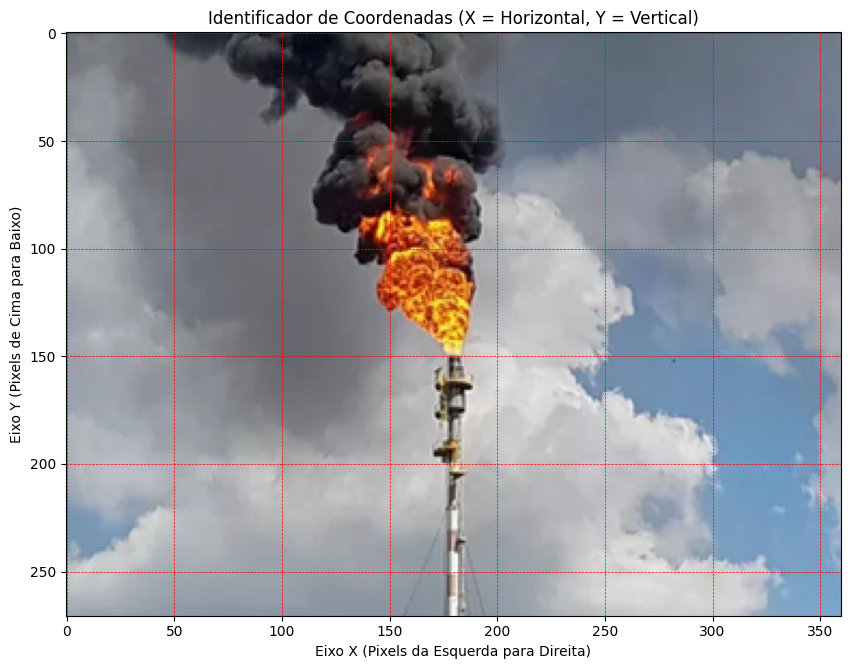

In [11]:
# Carregamento da imagem
caminho_imagem = 'imagem_pluma.jpg'
img_bgr = cv2.imread(caminho_imagem)

if img_bgr is None:
    raise ValueError(f"Não foi possível carregar a imagem em: {caminho_imagem}")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
altura, largura = img_rgb.shape[:2]
print(f"Dimensões da imagem: {largura} x {altura} pixels")

# Exibe a imagem com grade e eixos graduados para inspeção de coordenadas
plt.figure(figsize=(10, 8))
plt.imshow(img_rgb)
plt.grid(True, color='red', linestyle='--', linewidth=0.5)
plt.title('Identificador de Coordenadas (X = Horizontal, Y = Vertical)')
plt.xlabel('Eixo X (Pixels da Esquerda para Direita)')
plt.ylabel('Eixo Y (Pixels de Cima para Baixo)')
plt.show()

##Detecção com YOLOv5 e Definição da Bounding Box Manual


YOLOv5 não encontrou objetos detectáveis padrão.


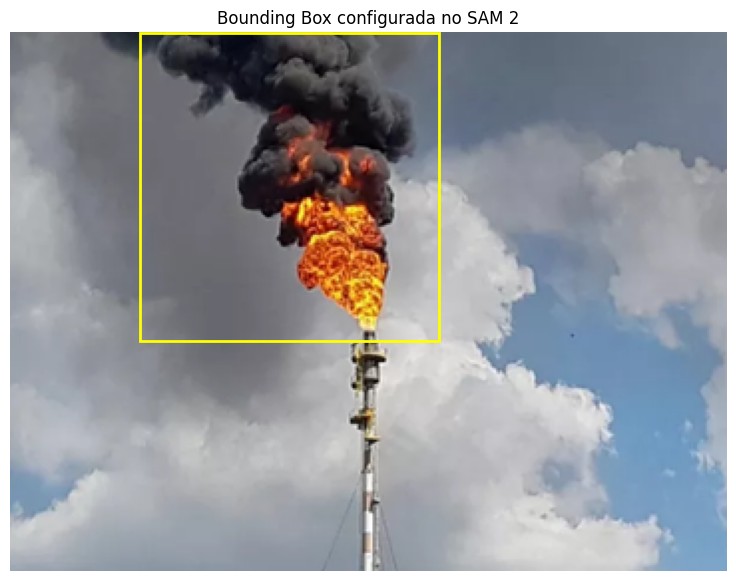

In [12]:
# Inspeção via YOLOv5
results = model_yolo(img_rgb)
detections = results.xyxy[0].cpu().numpy()

if len(detections) > 0:
    print("Detecções YOLOv5 encontradas:")
    for i, det in enumerate(detections):
        x1, y1, x2, y2, confianca, classe = det
        nome_classe = model_yolo.names[int(classe)]
        print(
            f"{i}: {nome_classe}, confiança={confianca:.3f}, "
            f"caixa={[round(v, 1) for v in [x1, y1, x2, y2]]}"
        )
    results.show()
else:
    print("YOLOv5 não encontrou objetos detectáveis padrão.")

# Definição manual da Bounding Box para delinear a pluma de fumaça
bbox_manual = np.array([65, 0, 215, 155], dtype=np.float32)
bbox_yolo = bbox_manual.copy()

x1, y1, x2, y2 = bbox_yolo

# Validação das coordenadas
if not (0 <= x1 < x2 <= largura and 0 <= y1 < y2 <= altura):
    raise ValueError("A bounding box está fora dos limites da imagem. Ajuste bbox_manual.")

# Visualização da Bounding Box sobre a imagem
plt.figure(figsize=(10, 7))
plt.imshow(img_rgb)
plt.gca().add_patch(
    plt.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="yellow", linewidth=2
    )
)
plt.title("Bounding Box configurada no SAM 2")
plt.axis("off")
plt.show()

# Prepara a imagem dentro do preditor SAM 2
predictor.set_image(img_rgb)

##Configuração e Visualização dos Prompts


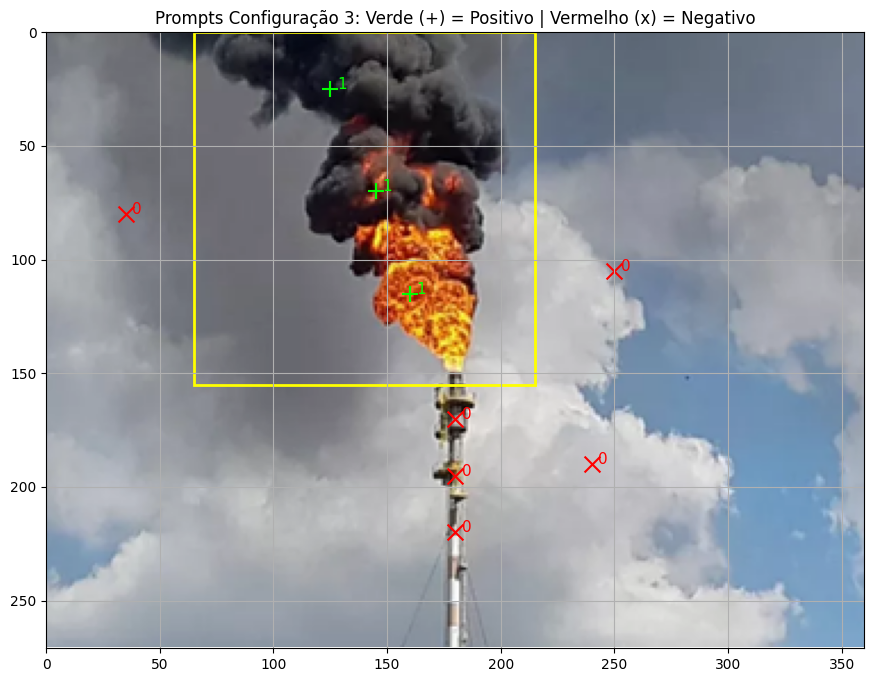

In [13]:
# CONFIGURAÇÃO 1: Apenas Bounding Box
pontos_c1 = None
labels_c1 = None

# CONFIGURAÇÃO 2: Bounding Box + 1 Ponto Positivo
pontos_c2 = np.array([[125, 25]], dtype=np.float32)
labels_c2 = np.array([1], dtype=np.int32)

# CONFIGURAÇÃO 3: Bounding Box + Pontos Positivos e Negativos
pontos_c3 = np.array([
    # Positivos: fumaça e chama
    [125, 25],
    [145, 70],
    [160, 115],
    # Negativos: céu e nuvens
    [35, 80],
    [250, 105],
    [240, 190],
    # Negativos: estrutura metálica
    [180, 170],
    [180, 195],
    [180, 220]
], dtype=np.float32)

labels_c3 = np.array([
    1, 1, 1,
    0, 0, 0,
    0, 0, 0
], dtype=np.int32)

# Visualização dos Prompts da Configuração 3
plt.figure(figsize=(12, 8))
plt.imshow(img_rgb)
plt.gca().add_patch(
    plt.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor="yellow", linewidth=2
    )
)

for ponto, rotulo in zip(pontos_c3, labels_c3):
    px, py = ponto
    cor = "lime" if rotulo == 1 else "red"
    marcador = "+" if rotulo == 1 else "x"

    plt.scatter(px, py, color=cor, marker=marcador, s=130)
    plt.text(px + 3, py, str(rotulo), color=cor, fontsize=11)

plt.xlim(0, largura)
plt.ylim(altura, 0)
plt.title("Prompts Configuração 3: Verde (+) = Positivo | Vermelho (x) = Negativo")
plt.grid(True)
plt.show()

##Função de Segmentação e Execução das Configurações

In [14]:
def segmentar_com_prompts(box, pontos=None, labels=None):
    kwargs = {
        "box": box,
        "multimask_output": True
    }
    if pontos is not None:
        kwargs["point_coords"] = pontos
        kwargs["point_labels"] = labels

    masks, scores, _ = predictor.predict(**kwargs)
    return masks.astype(bool), scores

# Execução da segmentação para cada configuração
masks_1, scores_1 = segmentar_com_prompts(bbox_yolo, pontos_c1, labels_c1)
masks_2, scores_2 = segmentar_com_prompts(bbox_yolo, pontos_c2, labels_c2)
masks_3, scores_3 = segmentar_com_prompts(bbox_yolo, pontos_c3, labels_c3)

##Funções de Visualização e Comparação

In [15]:
def mostrar_candidatas(img_rgb, masks, scores, nome_config):
    n_candidatas = len(scores)
    fig, axes = plt.subplots(1, n_candidatas, figsize=(5 * n_candidatas, 5))
    if n_candidatas == 1:
        axes = [axes]

    for i, ax in enumerate(axes):
        ax.imshow(masks[i], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Candidata {i + 1}\nScore = {scores[i]:.3f}")
        ax.axis("off")

    plt.suptitle(nome_config, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

def plotar_comparacao_lado_a_lado(img_rgb, mascara_binaria, titulo_config):
    mascara_binaria = np.asarray(mascara_binaria, dtype=bool)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Painel 1: Imagem Original
    axes[0].imshow(img_rgb)
    axes[0].set_title("1. Imagem Original")
    axes[0].axis("off")

    # Painel 2: Máscara Binária
    axes[1].imshow(mascara_binaria.astype(np.uint8), cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("2. Máscara Binária (Selecionado = 1)")
    axes[1].axis("off")

    # Painel 3: Overlay / Sobreposição
    overlay = img_rgb.copy()
    pixels_selecionados = mascara_binaria

    overlay[pixels_selecionados] = (
        0.6 * img_rgb[pixels_selecionados] + 0.4 * np.array([255, 0, 0])
    ).astype(np.uint8)

    contornos, _ = cv2.findContours(
        mascara_binaria.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )
    cv2.drawContours(overlay, contornos, -1, (255, 255, 255), 1)

    axes[2].imshow(overlay)
    axes[2].set_title("3. Máscara Sobreposta (Fumaça Destacada)")
    axes[2].axis("off")

    plt.suptitle(titulo_config, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

##Inspeção de Máscaras Candidatas

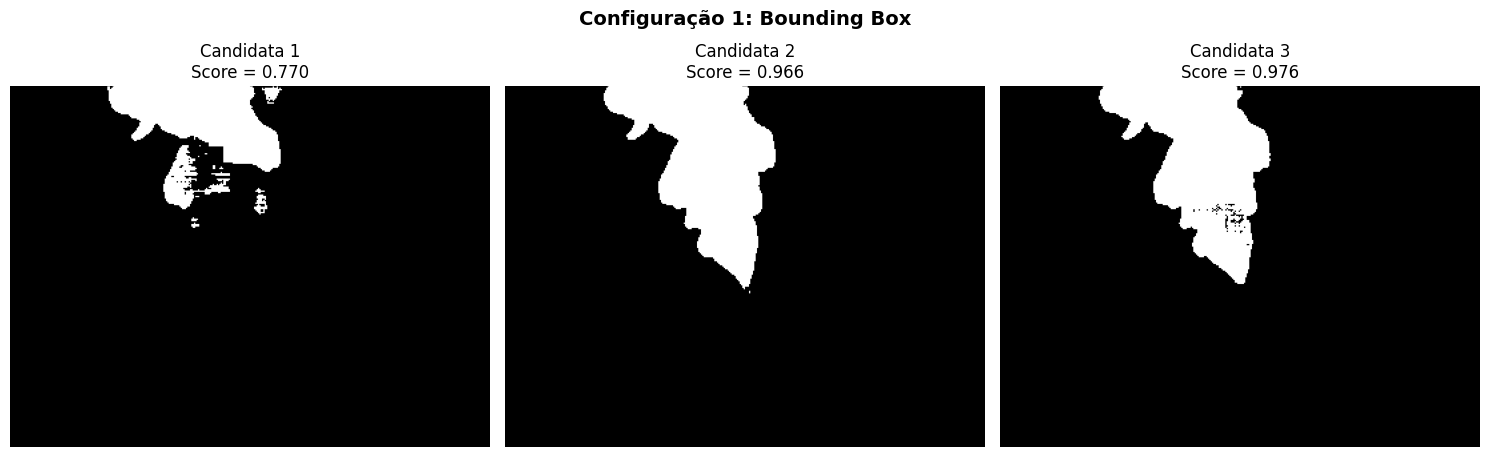

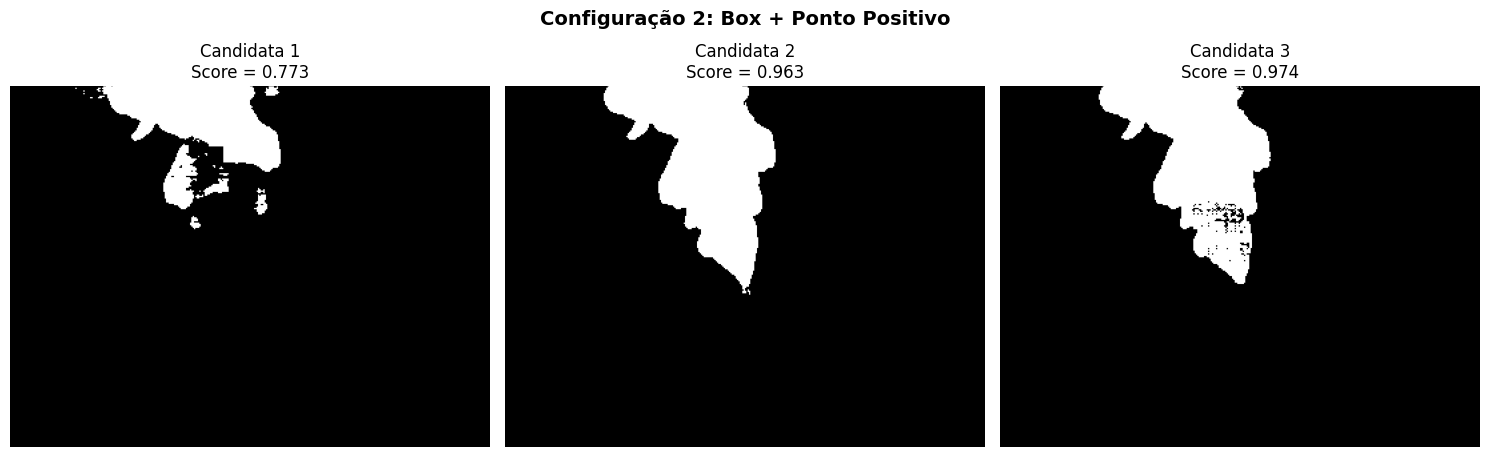

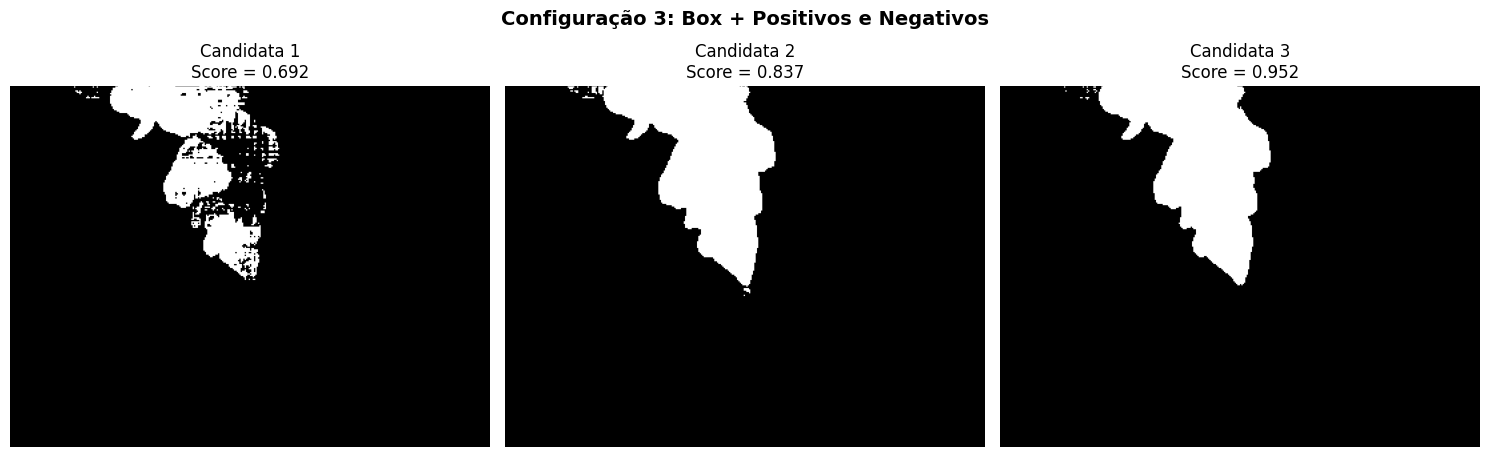

In [16]:
mostrar_candidatas(img_rgb, masks_1, scores_1, "Configuração 1: Bounding Box")
mostrar_candidatas(img_rgb, masks_2, scores_2, "Configuração 2: Box + Ponto Positivo")
mostrar_candidatas(img_rgb, masks_3, scores_3, "Configuração 3: Box + Positivos e Negativos")

##Exibição da Máscara de Maior Score por Configuração


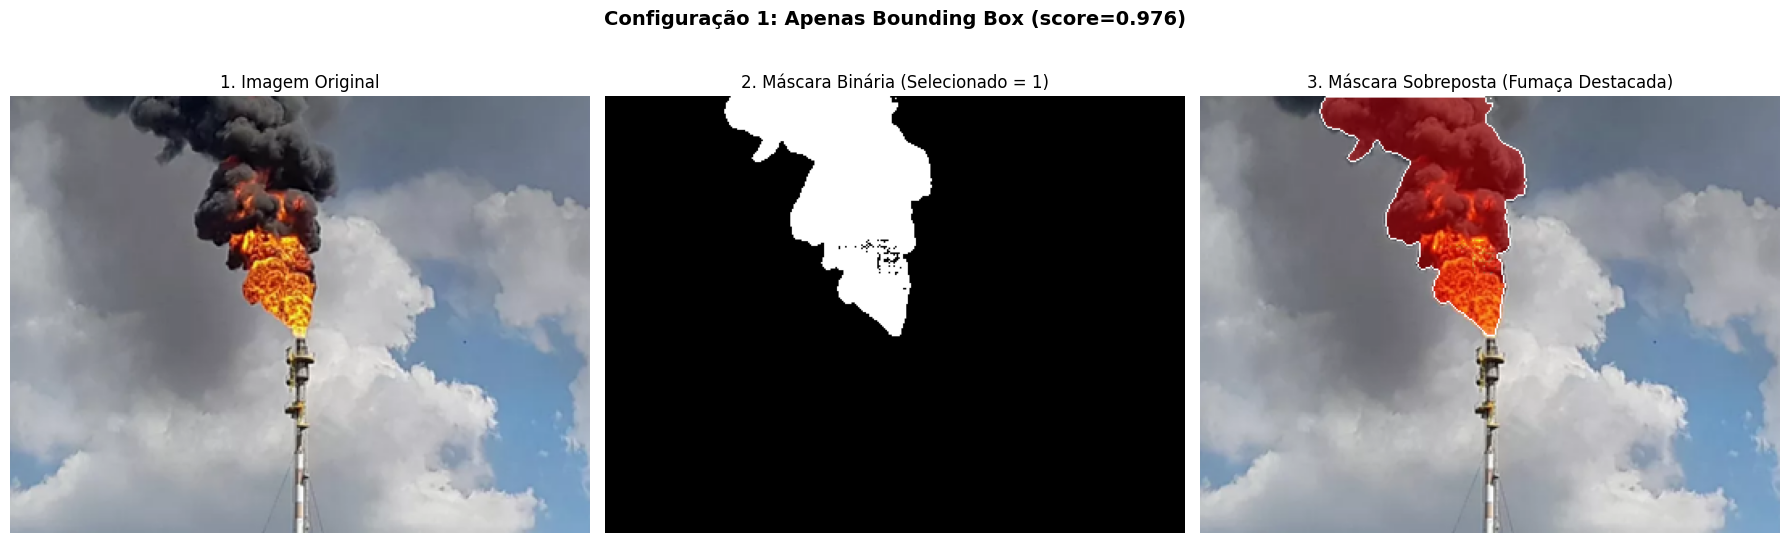

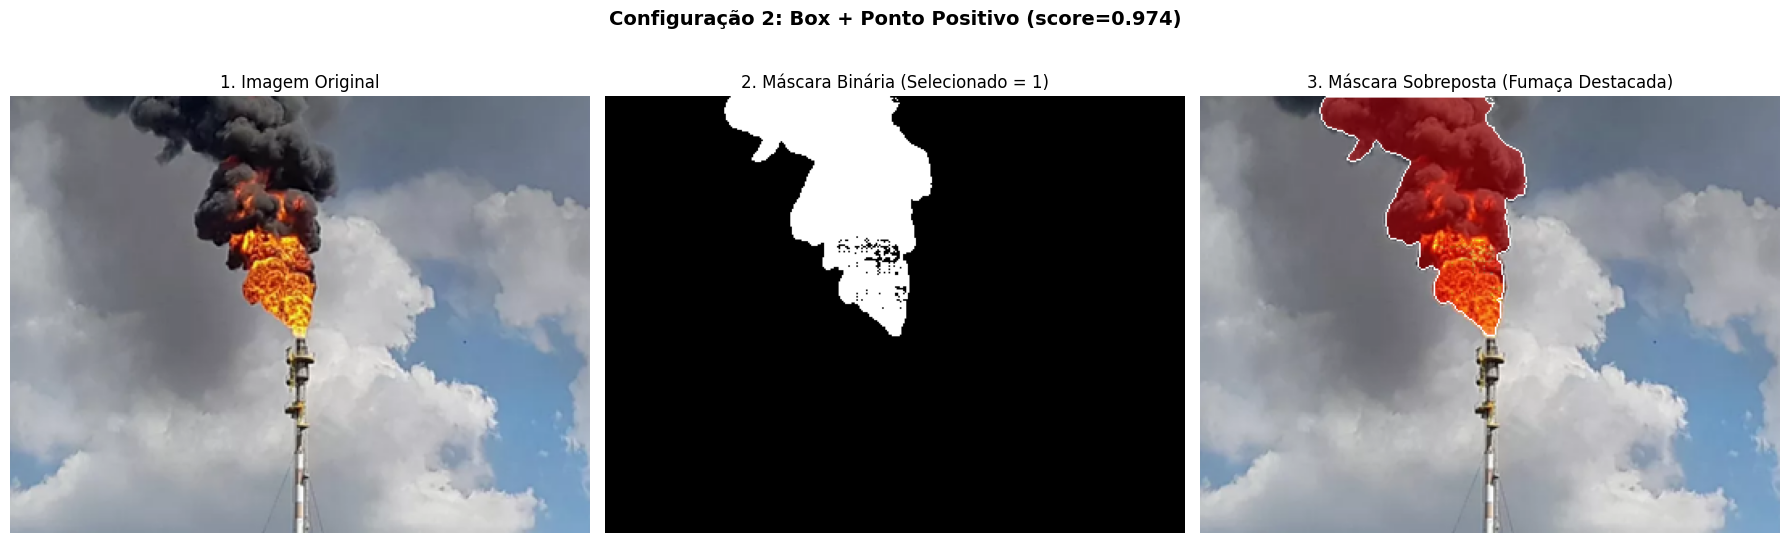

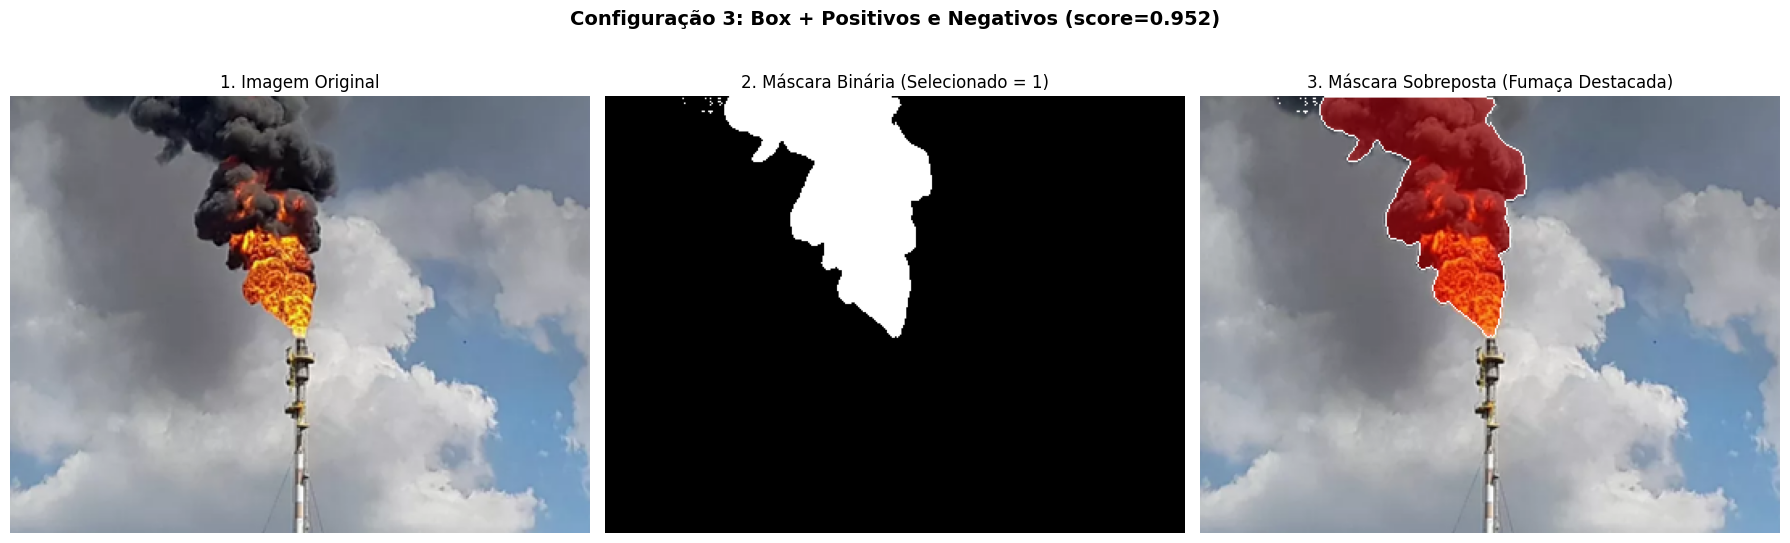

In [17]:
def selecionar_mascara(masks, scores):
    indice = int(np.argmax(scores))
    return masks[indice], float(scores[indice])

mascara_1, score_1 = selecionar_mascara(masks_1, scores_1)
mascara_2, score_2 = selecionar_mascara(masks_2, scores_2)
mascara_3, score_3 = selecionar_mascara(masks_3, scores_3)

plotar_comparacao_lado_a_lado(
    img_rgb, mascara_1,
    f"Configuração 1: Apenas Bounding Box (score={score_1:.3f})"
)

plotar_comparacao_lado_a_lado(
    img_rgb, mascara_2,
    f"Configuração 2: Box + Ponto Positivo (score={score_2:.3f})"
)

plotar_comparacao_lado_a_lado(
    img_rgb, mascara_3,
    f"Configuração 3: Box + Positivos e Negativos (score={score_3:.3f})"
)

**Avaliação das Configurações 1 e 2:**
Nestes primeiros testes, a máscara conseguiu cobrir quase toda a pluma e acertou bem os contornos. No entanto, apresentou algumas falhas (buracos) no meio da massa de fumaça, indicando que o modelo teve dificuldade de preenchimento interno sem pontos de auxílio.

**Avaliação da Configuração 3:**
Com a adição da caixa delimitadora (bounding box) combinada aos pontos positivos e negativos, o resultado melhorou significativamente. O modelo não incluiu nenhuma região indesejada de fundo (nuvens/céu) e o preenchimento interno foi corrigido.

**O que precisa ser melhorado:**
Apesar da Configuração 3 ter o melhor desempenho geral, em todas as tentativas (incluindo a terceira), uma pequena extremidade mais rala da pluma acabou ficando de fora. Para trabalhos futuros, seria necessário investigar como melhorar a detecção dessas partes mais finas e dispersas, talvez testando novos pesos no modelo ou aumentando a densidade de pontos positivos nessa área específica.

A maior dificuldade na segmentação desta imagem foi a falta de contraste nítido e a forte semelhança de textura e cor entre a pluma de fumaça e as nuvens ao fundo. Isso confundiu o modelo (SAM), fazendo com que as bordas da fumaça vazassem e incluíssem o céu azul ou as nuvens brancas como se fossem parte da pluma. Além disso, o modelo teve dificuldade no preenchimento interno da fumaça, gerando buracos (falsos negativos) na máscara.

Para contornar esses problemas, as configurações foram adaptadas ao longo dos testes. A principal justificativa de melhoria foi refinar o prompt: além da caixa delimitadora inicial (YOLO), passei a fornecer uma distribuição estratégica de pontos no SAM. Adicionei pontos negativos direcionados especificamente nas nuvens e no céu para forçar o limite da segmentação, e distribuí mais pontos positivos nas áreas internas e ralas da fumaça para garantir o preenchimento total e contínuo da máscara.

##Resumo Quantitativo em Tabela (DataFrame)

In [18]:
resumo = []

for nome, mascara, score in [
    ("Configuração 1", mascara_1, score_1),
    ("Configuração 2", mascara_2, score_2),
    ("Configuração 3", mascara_3, score_3)
]:
    resumo.append({
        "configuracao": nome,
        "score_sam": round(score, 4),
        "pixels_selecionados": int(mascara.sum()),
        "percentual_imagem_selecionada": round(100 * mascara.mean(), 2)
    })

df_resumo = pd.DataFrame(resumo)
display(df_resumo)

,configuracao,score_sam,pixels_selecionados,percentual_imagem_selecionada
0,Configuração 1,0.9757,9828,10.07
1,Configuração 2,0.9738,9701,9.94
2,Configuração 3,0.9524,10046,10.30
